In [1]:
import gc, json, math, random, shutil, sys, traceback
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from tqdm.auto import tqdm

sys.path.insert(0, "kev")
from models.kev_pointer import KevPointerModel

BASE_MODEL = "jaredpalmer/kev-0.8b"
LORA_RANK = 64
device = "cuda"

In [2]:
import importlib
import data.persona as _persona_mod
import data.base as _base_mod
import data.issp as _issp_mod
import data.twin2k as _twin2k_mod
import data.grummon2025 as _grummon2025_mod
for _mod in (_persona_mod, _base_mod, _issp_mod, _twin2k_mod, _grummon2025_mod):
    importlib.reload(_mod)

from data.base import (
    PAIR_PERSONA_ATTRS,
    SINGLE_PERSONA_ATTRS,
    build_persona_dataset,
    evaluate_model,
    group_train_records,
    load_split_qids,
    make_grouped_view,
    make_view,
)
from data.issp import load_issp_df, load_issp_eval
from data.twin2k import load_twin2k_df
from data.grummon2025 import load_grummon2025

# 1. Load question-ID splits in the notebook ({"train": ["2015:v1", ...], "valid": [...], "test": [...]})
issp_qids = load_split_qids("splits/split.json")

# 2. Pass training question IDs to dataset loaders
issp_train_df = load_issp_df(qids=issp_qids["train"])
twin_df = load_twin2k_df()  # qids=None loads all Twin-2K-500 questions
train_df = pd.concat([issp_train_df, twin_df], ignore_index=True)

print(
    f"train : {len(train_df):>9,} answers across {train_df['qid'].nunique():>4} questions "
    f"(ISSP={len(issp_qids['train'])}, Twin2K={twin_df['qid'].nunique()})\n"
    f"valid : {len(issp_qids['valid']):>4} ISSP questions\n"
    f"test  : {len(issp_qids['test']):>4} ISSP questions"
)

train : 1,737,940 answers across 1468 questions (ISSP=494, Twin2K=974)
valid :   50 ISSP questions
test  :   72 ISSP questions


## Build persona datasets

In [3]:
INCLUDE_COUNTRY = False
TEST10_SEED = 42

# MIN_N = 100
# 1. Build (or load from .cache/) ISSP + Twin-2K-500 training sets
# train_records_k1 = build_persona_dataset(
#     train_df, attr_sets=SINGLE_PERSONA_ATTRS, include_country=INCLUDE_COUNTRY, min_n=MIN_N, desc="train_records_k1"
# )
# train_records_k2 = build_persona_dataset(
#     train_df, attr_sets=PAIR_PERSONA_ATTRS, include_country=INCLUDE_COUNTRY, min_n=MIN_N, desc="train_records_k2"
# )
train_records_issp_twin2k_resp = build_persona_dataset(
    train_df, attr_sets=None, include_country=INCLUDE_COUNTRY, desc="train_records_resp"
)

# 2. Build validation and test evaluation sets (respondent-level: attr_sets=None)
issp_test10_qids = random.Random(TEST10_SEED).sample(sorted(issp_qids["test"]), 10)

issp_resp_valid_grouped = load_issp_eval(
    qids=issp_qids["valid"], attr_sets=None, include_country=INCLUDE_COUNTRY, grouped=True, name="valid", valid=False
)
issp_resp_test_grouped = load_issp_eval(
    qids=issp_qids["test"], attr_sets=None, include_country=INCLUDE_COUNTRY, grouped=True, name="test", valid=False
)
issp_resp_test10_grouped = load_issp_eval(
    qids=issp_test10_qids, attr_sets=None, include_country=INCLUDE_COUNTRY, grouped=True, name="test_10", valid=True
)
grummon2025_grouped = load_grummon2025(
    attr_sets=None, include_country=INCLUDE_COUNTRY, grouped=True, valid=False
)

valid_records = issp_resp_valid_grouped["records"]
test_records = issp_resp_test_grouped["records"]
test10_records = issp_resp_test10_grouped["records"]
grummon2025_records = grummon2025_grouped["records"]

print(
    f"Eval sets        : valid={len(valid_records):,} ({len(issp_resp_valid_grouped['packed_views']):,} states), "
    f"test={len(test_records):,} ({len(issp_resp_test_grouped['packed_views']):,} states), "
    f"test_10={len(test10_records):,} ({len(issp_resp_test10_grouped['packed_views']):,} states), "
    f"grummon2025={len(grummon2025_records):,} ({len(grummon2025_grouped['packed_views']):,} states)"
)

Loaded 1,737,940 records from train_records_resp_minNone_d98864c0.pkl
Loaded 64,201 records from valid_records_minNone_eaa9b07e.pkl
Loaded 92,992 records from test_records_minNone_6a10f9dc.pkl
Loaded 13,006 records from test_10_records_minNone_4228e0b9.pkl
Eval sets        : valid=64,201 (14,236 states), test=92,992 (14,263 states), test_10=13,006 (8,026 states), grummon=33,798 (3,652 states)


### Preview

In [18]:
# Intuitive demo on 1 respondent who answered short, medium, and very long questions (21 questions total):
target_personas = next(r["personas"] for r in train_records_issp_twin2k_resp if r["qid"] == "twin2k:QID57")
one_resp_all = [r for r in train_records_issp_twin2k_resp if r["personas"] == target_personas]
one_resp_all.sort(key=lambda r: len(r["question"]) + sum(len(str(o)) for o in r["option_texts"]))
demo_recs = one_resp_all[:12] + one_resp_all[len(one_resp_all) // 2 : len(one_resp_all) // 2 + 6] + one_resp_all[-3:]

sample_groups = group_train_records(demo_recs, max_questions=8, max_chars=2400, rng=None)
demo_rows = []
for g_idx, g in enumerate(sample_groups):
    char_lens = [len(r["question"]) + sum(len(str(o)) for o in r["option_texts"]) for r in g]
    demo_rows.append({
        "group_idx": g_idx,
        "n_questions": len(g),
        "total_chars": sum(char_lens),
        "question_char_lens": char_lens,
        "qids": [r["qid"] for r in g],
        "why_group_closed": (
            "hit max_questions=8" if len(g) == 8
            else ("last group (remainder)" if g_idx == len(sample_groups) - 1 else "next question would exceed max_chars=2400")
        ),
    })
df_demo = pd.DataFrame(demo_rows)
print(
    f"1 respondent with {len(demo_recs)} questions -> packed into {len(sample_groups)} groups "
    f"(sum of n_questions = {df_demo['n_questions'].sum()}, 0 questions cut off or dropped):"
)
display(df_demo)

rng = random.Random(0)
sample_grouped_view = make_grouped_view(sample_groups[0], rng=rng)
sample_grouped_view

1 respondent with 21 questions -> packed into 5 groups (sum of n_questions = 21, 0 questions cut off or dropped):


,group_idx,n_questions,total_chars,question_char_lens,qids,why_group_closed
0,0,8,768,"[56, 82, 94, 101, 105, 109, 110, 111]","[twin2k:QID148, twin2k:QID169, twin2k:QID165, ...",hit max_questions=8
1,1,8,1857,"[112, 113, 116, 117, 348, 350, 350, 351]","[twin2k:QID67, twin2k:QID63, twin2k:QID83, twi...",hit max_questions=8
2,2,3,2318,"[352, 354, 1612]","[twin2k:QID234_6, twin2k:QID235_2, twin2k:QID58]",next question would exceed max_chars=2400
3,3,1,1675,[1675],[twin2k:QID59],next question would exceed max_chars=2400
4,4,1,2311,[2311],[twin2k:QID57],last group (remainder)


{'state': 'Age: 30-49\nRegion: Midwest\nIncome: $50,000 - $75,000\nPolitical ideology: Moderate\nRace: Black\nEducation: High school or some college\nReligion: Nothing in particular\nMain activity: Part-time employment\nPolitical party: Independent\nAttendance of religious services: A few times a year\nSex: Female\nHow many people, including yourself, live in your household?: 3\nMarital status: Married',
 'questions': {'0:twin2k:QID148': {'type': 'choice',
   'instructions': 'I am purposely trying to lose weight by eating less',
   'criteria': {'Yes': None, 'No': None},
   'target': {'Yes': 1.0, 'No': 0.0}},
  '1:twin2k:QID169': {'type': 'choice',
   'instructions': 'Is the tallest redwood tree in the world more or less than 1000 feet tall?',
   'criteria': {'more': None, 'less': None},
   'target': {'more': 1.0, 'less': 0.0}},
  '2:twin2k:QID165': {'type': 'choice',
   'instructions': 'Do you think there are more or fewer than 65 African countries in the United Nations?',
   'criteria

## Functions (Grouped Shared-Prefix Training)

In [4]:
import importlib
import time
from IPython.display import HTML
import data.base as _base_mod
import models.kev_pointer as _kev_pointer_mod
importlib.reload(_base_mod)
importlib.reload(_kev_pointer_mod)
from data.base import CudaGraphs, evaluate_model, group_train_records, make_grouped_view, make_view
from models.kev_pointer import Checkpoint, KevPointerModel, LoadOptions


def free_gpu():
    if hasattr(sys, "last_traceback") and sys.last_traceback is not None:
        traceback.clear_frames(sys.last_traceback)
        sys.last_traceback = None
    for attr in ("last_value", "last_type", "last_exc"):
        if hasattr(sys, attr):
            setattr(sys, attr, None)
    gc.collect()
    torch.cuda.empty_cache()


def save_checkpoint(model, save_dir, name, extra):
    """Atomically write checkpoint to save_dir / name via a temporary directory."""
    save_dir = Path(save_dir)
    folder, tmp = save_dir / name, save_dir / f"{name}-tmp"
    shutil.rmtree(tmp, ignore_errors=True)
    model.save(tmp, extra=extra)
    (tmp / "metrics.json").write_text(json.dumps(extra, indent=2) + "\n")
    shutil.rmtree(folder, ignore_errors=True)
    tmp.rename(folder)


def load_checkpoint(ckpt_dir, device="cuda", trainable=False):
    ckpt_dir = Path(ckpt_dir)
    if not (ckpt_dir / "head.pt").exists():
        raise FileNotFoundError(f"Checkpoint not found: {ckpt_dir / 'head.pt'}")
    free_gpu()
    if trainable:
        m = KevPointerModel.build(str(ckpt_dir), device=device)
        m.net.head.temperature = 1.0
        return m
    ck = Checkpoint(str(ckpt_dir))
    tok, net = ck.load(device, LoadOptions(dtype=torch.bfloat16, temperature=1.0, cuda_graphs=True, fused=True))
    m = KevPointerModel(net, tok, ck.meta, "loaded")
    m.net.head.temperature = 1.0
    return m


def _normalize_eval_sets(eval_records):
    """Normalize `eval_records` into a list of grouped bundle dicts and verify exactly one has `valid=True`."""
    if isinstance(eval_records, dict) and "records" in eval_records:
        eval_records["valid"] = True
        eval_sets = [eval_records]
    elif isinstance(eval_records, (list, tuple)):
        eval_sets = list(eval_records)
    else:
        raise ValueError("eval_records must be a grouped evaluation dict or a list of grouped evaluation dicts")

    if not eval_sets:
        raise ValueError("eval_records must not be empty")
    for s in eval_sets:
        if not isinstance(s, dict) or not s.get("name"):
            raise ValueError("Each evaluation set must be a grouped dict with a non-empty 'name'")
        if "valid" not in s:
            raise KeyError(f"Evaluation set {s['name']!r} is missing required 'valid' boolean flag")

    valid_sets = [s for s in eval_sets if s["valid"]]
    if len(valid_sets) != 1:
        raise ValueError(
            f"Exactly one evaluation set in eval_records must have valid=True, got {len(valid_sets)}: "
            f"{[(s['name'], s['valid']) for s in eval_sets]}"
        )
    return eval_sets, valid_sets[0]["name"]


def _fmt_time(seconds):
    if not math.isfinite(seconds) or seconds < 0:
        return "--:--"
    seconds = int(round(seconds))
    h, rem = divmod(seconds, 3600)
    m, s = divmod(rem, 60)
    return f"{h:d}:{m:02d}:{s:02d}" if h > 0 else f"{m:02d}:{s:02d}"


class TrainingPlotter:
    PALETTE = ["tab:orange", "tab:green", "tab:purple", "tab:red", "tab:brown"]

    def __init__(self, total_steps, log_every, eval_sets, val_name, run_name="train"):
        self.run_name = run_name
        self.total_steps = total_steps
        self.log_every = log_every
        self.val_name = val_name
        self.start_time = time.perf_counter()
        self.train_start_time = None
        self.train_start_step = 0
        self.last_lr = None
        self.eval_specs = [
            {
                "name": s["name"],
                "valid": bool(s["valid"]),
                "n_records": len(s["records"]),
                "n_states": len(s["packed_views"]),
                "has_ols": s.get("eval_fn") is not None,
            }
            for s in eval_sets
        ]
        self.ols_names = [sp["name"] for sp in self.eval_specs if sp["has_ols"]]
        self.window_kls = []
        self.val_rows = []
        self.latest_ols_df = {}
        self.latest_ols_summary = {}
        self.history = {
            "step": [],
            "step_kl": [],
            "logged_step": [],
            "window_kl": [],
            "val_step": [],
            "eval_kls": {sp["name"]: [] for sp in self.eval_specs},
        }

        self.status_handle = display(HTML(""), display_id=True)
        n_plots = 1 + len(self.eval_specs) + len(self.ols_names)
        self.fig, axes = plt.subplots(n_plots, 1, figsize=(10, 3.4 * n_plots))
        if n_plots == 1:
            axes = [axes]
        self.ax_train = axes[0]
        self.ax_evals = {
            sp["name"]: axes[1 + i] for i, sp in enumerate(self.eval_specs)
        }
        self.ax_ols = {
            name: axes[1 + len(self.eval_specs) + j] for j, name in enumerate(self.ols_names)
        }
        self.handle = display(self.fig, display_id=True)
        plt.close(self.fig)
        self.table_handle = display(pd.DataFrame(), display_id=True)
        self.ols_table_handle = display(pd.DataFrame(), display_id=True) if self.ols_names else None

    def update_status(self, step, epoch=0, status="training", lr=None):
        if lr is not None:
            self.last_lr = lr
        now = time.perf_counter()
        elapsed = now - self.start_time
        pct = 100.0 * step / max(1, self.total_steps)
        if self.train_start_time is not None and step > self.train_start_step:
            train_elapsed = now - self.train_start_time
            steps_done = step - self.train_start_step
            rate = steps_done / max(1e-6, train_elapsed)
            eta = (self.total_steps - step) / max(1e-6, rate)
            rate_str = f"{rate:.2f} step/s"
            eta_str = _fmt_time(eta)
        else:
            rate_str = "-- step/s"
            eta_str = "--:--"

        kl_str = f"{self.history['window_kl'][-1]:.4f}" if self.history["window_kl"] else "—"
        lr_str = f"{self.last_lr:.2e}" if self.last_lr is not None else "—"
        bar_color = "#f59e0b" if status.startswith("eval") else "#2563eb"
        html = (
            f"<div style='font-family: monospace; font-size: 13px; padding: 8px 10px; "
            f"border: 1px solid #cbd5e1; border-radius: 6px; background: #f8fafc; color: #0f172a; margin: 4px 0;'>"
            f"<div style='margin-bottom: 5px;'>"
            f"<b>{self.run_name}</b> &nbsp;|&nbsp; Epoch <b>{epoch}</b> &nbsp;|&nbsp; "
            f"Step <b>{step:,} / {self.total_steps:,}</b> (<b>{pct:.2f}%</b>) &nbsp;|&nbsp; "
            f"Elapsed: {_fmt_time(elapsed)} &lt; ETA: {eta_str} ({rate_str}) &nbsp;|&nbsp; "
            f"train_kl: <b>{kl_str}</b> &nbsp;|&nbsp; lr: {lr_str} &nbsp;|&nbsp; "
            f"<span style='color: {bar_color}; font-weight: bold;'>[{status}]</span>"
            f"</div>"
            f"<div style='width: 100%; height: 12px; background: #e2e8f0; border-radius: 4px; overflow: hidden;'>"
            f"<div style='width: {min(100.0, max(0.2 if step > 0 else 0.0, pct)):.3f}%; height: 100%; background: {bar_color};'></div>"
            f"</div></div>"
        )
        self.status_handle.update(HTML(html))

    def flush_window(self, step):
        """Flush any accumulated `window_kls` so runs or eval intervals shorter than `log_every` have a valid `window_kl`."""
        if self.window_kls:
            mean_kl = sum(self.window_kls) / len(self.window_kls)
            self.history["logged_step"].append(step)
            self.history["window_kl"].append(mean_kl)
            self.window_kls = []
            return mean_kl
        return self.history["window_kl"][-1] if self.history["window_kl"] else None

    def log_step(self, step, step_kls, epoch=1, lr=None):
        if self.train_start_time is None:
            self.train_start_time = time.perf_counter() - 0.25
            self.train_start_step = step - 1
        self.window_kls.extend(step_kls)
        self.history["step"].append(step)
        self.history["step_kl"].append(sum(step_kls) / len(step_kls))
        mean_kl = None
        if step % self.log_every == 0:
            mean_kl = self.flush_window(step)
            self.redraw(step)
        if step == 1 or step % 5 == 0 or mean_kl is not None:
            self.update_status(step, epoch=epoch, status="training", lr=lr)
        return mean_kl

    def log_eval(self, step, eval_summaries, eval_extra_dfs, epoch=0):
        if step > 0 and self.window_kls:
            self.flush_window(step)
        self.history["val_step"].append(step)
        train_kl = self.history["window_kl"][-1] if self.history["window_kl"] else np.nan
        row = {
            "epoch": epoch,
            "step": step,
            "train_kl": train_kl,
        }
        for sp in self.eval_specs:
            name = sp["name"]
            s = eval_summaries[name]
            kl = float(s["dist_kl"])
            self.history["eval_kls"][name].append(kl)
            row[f"{name}_kl"] = kl
            if sp["has_ols"]:
                for k in ("OLS MAPE (%)", "OLS MAE", "OLS MSE", "Spearman rho"):
                    if k in s:
                        row[f"{name}_{k}"] = float(s[k])
                self.latest_ols_summary[name] = s
                if name in eval_extra_dfs and eval_extra_dfs[name] is not None:
                    self.latest_ols_df[name] = eval_extra_dfs[name]

        self.val_rows.append(row)
        self.redraw(step)
        self.redraw_table()

    def redraw_table(self):
        df = pd.DataFrame(self.val_rows)
        val_col = f"{self.val_name}_kl"
        best_idx = df[val_col].idxmin()
        fmt = {c: "{:.4f}" for c in df.columns if c not in ("epoch", "step")}
        for c in df.columns:
            if "MAPE" in c:
                fmt[c] = "{:.2f}"
        styled = (
            df.style
            .apply(
                lambda r: [
                    "background-color: #d4edda; color: #155724; font-weight: bold"
                    if r.name == best_idx else ""
                    for _ in r
                ],
                axis=1,
            )
            .format(fmt, na_rep="—")
        )
        self.table_handle.update(styled)

        if self.ols_table_handle is not None and self.latest_ols_df:
            name = self.ols_names[0]
            if name in self.latest_ols_df:
                ols_df = self.latest_ols_df[name].copy()
                self.ols_table_handle.update(ols_df.style.format("{:.4f}"))

    def redraw(self, step):
        self.ax_train.clear()
        if self.history["logged_step"]:
            self.ax_train.plot(
                self.history["logged_step"],
                self.history["window_kl"],
                color="tab:blue",
                linewidth=2,
                label=f"train KL (mean over {self.log_every} steps)",
            )
            self.ax_train.set_yscale("log")
            self.ax_train.legend(loc="upper right")
        self.ax_train.set_ylabel("Train KL (bits)")
        self.ax_train.set_title(f"Training KL — step {step}/{self.total_steps}")
        self.ax_train.set_xlabel("Step")

        for i, sp in enumerate(self.eval_specs):
            name = sp["name"]
            ax = self.ax_evals[name]
            ax.clear()
            kls = self.history["eval_kls"][name]
            color = self.PALETTE[i % len(self.PALETTE)]
            if kls:
                best_kl = min(kls)
                ax.plot(
                    self.history["val_step"],
                    kls,
                    color=color,
                    marker="o",
                    linewidth=2,
                    label=f"{name} KL (best={best_kl:.4f} bits, last={kls[-1]:.4f})",
                )
                ax.set_yscale("log")
                ax.legend(loc="upper right")
            tag = " [VALID — saves best]" if sp["valid"] else ""
            ax.set_ylabel(f"{name} KL (bits)")
            ax.set_xlabel("Step")
            ax.set_title(f"{name}{tag} ({sp['n_records']:,} records, {sp['n_states']:,} states)")

        for name in self.ols_names:
            ax = self.ax_ols[name]
            ax.clear()
            if name in self.latest_ols_df:
                bdf = self.latest_ols_df[name]
                arms = list(bdf.index)
                x = np.arange(len(arms))
                width = 0.36
                ax.bar(x - width / 2, bdf["human"].values, width, label="Human RCT", color="tab:gray")
                ax.bar(x + width / 2, bdf["model"].values, width, label=f"Model (step {step})", color="tab:green")
                ax.axhline(0.0, color="black", linewidth=0.8, linestyle="--")
                ax.set_xticks(x)
                ax.set_xticklabels(arms, rotation=15, ha="right")
                ax.set_ylabel("OLS Treatment Effect (vs. Positive)")
                s = self.latest_ols_summary.get(name, {})
                mape = s.get("OLS MAPE (%)", float("nan"))
                mae = s.get("OLS MAE", float("nan"))
                rho = s.get("Spearman rho", float("nan"))
                ax.set_title(
                    f"{name} Current Model OLS Betas — MAPE={mape:.2f}%, MAE={mae:.4f}, Spearman rho={rho:.3f}"
                )
                ax.legend(loc="upper right")

        self.fig.tight_layout()
        self.handle.update(self.fig)


def train_one_step(model, macro_batch, batch_size, optimizer, scheduler, rng, step, total_steps):
    """Run one optimizer step over `macro_batch` of persona groups using shared-prefix forward/backward."""
    total_questions = sum(len(g) for g in macro_batch)
    step_kls = []
    for sub_start in range(0, len(macro_batch), batch_size):
        batch_groups = macro_batch[sub_start:sub_start + batch_size]
        prepared = [model.prepare(make_grouped_view(g, rng=rng)) for g in batch_groups]
        logits_batch = model.forward([enc for enc, _ in prepared], shared_prefix=True)

        losses = []
        for (_, targets), record_logits in zip(prepared, logits_batch):
            for z, q in zip(record_logits, targets):
                t = q["target"].to(device)
                logp = torch.log_softmax(z.float(), dim=-1)
                losses.append(-(t * logp).sum())
                nz = t > 0
                step_kls.append(((t[nz] * (t[nz].log() - logp[nz])).sum() / math.log(2)).item())

        loss = torch.stack(losses).sum() / total_questions
        loss.backward()

    grad_norm = torch.nn.utils.clip_grad_norm_(model.trainable_parameters(), 1.0)
    if torch.isfinite(grad_norm):
        optimizer.step()
    else:
        print(f"Skipping optimizer.step() at step {step + 1}: non-finite grad_norm={grad_norm.item()}")
    if step + 1 < total_steps:
        scheduler.step()
    optimizer.zero_grad(set_to_none=True)
    return step_kls


def train_stage(
    model,
    train_records,
    eval_records,
    save_dir,
    *,
    init_from,
    epochs,
    lr=1e-4,
    pct_start=0.1,
    batch_size=1,
    grad_accum_steps=12,
    max_questions_per_group=8,
    max_chars_per_group=2400,
    eval_batch_size=128,
    log_every=20,
    val_every=200,
    samples_per_epoch=None,
    seed=0,
    resume=False,
):
    """Grouped shared-prefix training stage.

    - Groups `train_records` by persona state into length-matched chunks of up to `max_questions_per_group` questions
      (and `max_chars_per_group` padded question+option characters to bound peak VRAM without gradient checkpointing).
    - Shuffles persona attributes at the group level (`make_grouped_view(g, rng=rng)`).
    - Runs each group's shared state once and branches its questions via `model.forward(..., shared_prefix=True)`.
    """
    if model is None:
        raise ValueError("model must be loaded before calling train_stage")

    if model.net.graphs is not None:
        model.net.graphs = None
    free_gpu()

    eval_sets, val_name = _normalize_eval_sets(eval_records)
    save_dir = Path(save_dir)
    rng = random.Random(seed)
    effective_groups_bs = batch_size * grad_accum_steps
    n_per_epoch = min(samples_per_epoch, len(train_records)) if samples_per_epoch else len(train_records)

    # Build initial groups with an independent RNG to determine steps_per_epoch without mutating `rng`
    probe_records = random.Random(seed).sample(train_records, n_per_epoch) if samples_per_epoch else train_records
    probe_groups = group_train_records(
        probe_records, max_questions=max_questions_per_group, max_chars=max_chars_per_group, rng=None
    )
    steps_per_epoch = math.ceil(len(probe_groups) / effective_groups_bs)
    total_steps = epochs * steps_per_epoch
    del probe_records, probe_groups

    state_path = save_dir / "last" / "trainer_state.pt"
    if resume and not state_path.exists():
        raise FileNotFoundError(f"Cannot resume: {state_path} does not exist")

    optimizer = torch.optim.AdamW(model.trainable_parameters(), lr=lr, weight_decay=0.01)
    scheduler = torch.optim.lr_scheduler.OneCycleLR(optimizer, max_lr=lr, total_steps=total_steps, pct_start=pct_start)
    plotter = TrainingPlotter(total_steps, log_every, eval_sets, val_name, run_name=save_dir.name)

    def run_all_evals(cur_epoch):
        summaries = {}
        extra_dfs = {}
        # Share a single CudaGraphs instance across all eval sets in this validation pass, then free it once in finally
        model.net.graphs = CudaGraphs(model.net.lm, model.net.pad_id)
        try:
            for idx, s in enumerate(eval_sets, start=1):
                name = s["name"]
                plotter.update_status(step, epoch=cur_epoch, status=f"eval ({idx}/{len(eval_sets)}): {name}...")
                summary, _ = evaluate_model(model, s, batch_size=eval_batch_size, show_progress=False)
                summaries[name] = summary
                extra_dfs[name] = s.get("last_extra_df")
        finally:
            model.net.graphs = None
            free_gpu()
        return summaries, extra_dfs

    if resume:
        st = torch.load(state_path, map_location="cpu", weights_only=False)
        step = st["step"]
        start_epoch = st["epoch"]
        resume_start_idx = st["next_start"]
        best_val_kl = st["best_val_kl"]
        resume_rng_state = st["rng_state"]
        epoch_rng_state_saved = st.get("epoch_rng_state")
        epoch_groups_saved = st.get("epoch_records")
        optimizer.load_state_dict(st["optimizer"])
        scheduler.load_state_dict(st["scheduler"])
        plotter.history = st["history"]
        plotter.val_rows = st["val_rows"]
        plotter.latest_ols_df = st.get("latest_ols_df", {})
        plotter.latest_ols_summary = st.get("latest_ols_summary", {})
        plotter.redraw(step)
        plotter.redraw_table()
        plotter.update_status(step, epoch=start_epoch + 1, status="resumed", lr=scheduler.get_last_lr()[0])
        print(f"Resumed {save_dir.name} at epoch {start_epoch + 1}, step {step}/{total_steps} (best_{val_name}_kl={best_val_kl:.4f})")
    else:
        step = 0
        start_epoch = 0
        resume_start_idx = 0
        resume_rng_state = None
        epoch_rng_state_saved = None
        epoch_groups_saved = None
        summaries_0, extra_dfs_0 = run_all_evals(cur_epoch=0)
        best_val_kl = float(summaries_0[val_name]["dist_kl"])
        plotter.log_eval(0, summaries_0, extra_dfs_0, epoch=0)
        plotter.update_status(0, epoch=1, status="starting epoch 1...")

    def validate_and_save(epoch_idx, next_start, n_epoch_groups, epoch_rng_state):
        nonlocal best_val_kl
        summaries, extra_dfs = run_all_evals(cur_epoch=epoch_idx + 1)
        val_summary = summaries[val_name]
        val_ce = float(val_summary["ce"])
        val_kl = float(val_summary["dist_kl"])
        plotter.log_eval(step, summaries, extra_dfs, epoch=epoch_idx + 1)

        train_kl = float(plotter.history["window_kl"][-1])
        extra = {
            "init_from": str(init_from),
            "step": step,
            "epoch": epoch_idx + 1,
            "val_set": val_name,
            "train_kl": train_kl,
            "val_ce": val_ce,
            "val_dist_kl": val_kl,
            "eval_metrics": {name: {k: float(v) for k, v in s.items()} for name, s in summaries.items()},
            "settings": {
                "lr": lr,
                "pct_start": pct_start,
                "batch_size": batch_size,
                "grad_accum_steps": grad_accum_steps,
                "effective_groups_per_step": effective_groups_bs,
                "max_questions_per_group": max_questions_per_group,
                "max_chars_per_group": max_chars_per_group,
                "epochs": epochs,
                "samples_per_epoch": samples_per_epoch,
                "seed": seed,
            },
        }
        if val_kl < best_val_kl:
            best_val_kl = val_kl
            save_checkpoint(model, save_dir, "best", extra=extra)
        save_checkpoint(model, save_dir, "last", extra=extra)

        at_epoch_end = next_start >= n_epoch_groups
        torch.save({
            "step": step,
            "epoch": epoch_idx + 1 if at_epoch_end else epoch_idx,
            "next_start": 0 if at_epoch_end else next_start,
            "best_val_kl": best_val_kl,
            "rng_state": rng.getstate(),
            "epoch_rng_state": None if at_epoch_end else epoch_rng_state,
            "optimizer": optimizer.state_dict(),
            "scheduler": scheduler.state_dict(),
            "history": plotter.history,
            "val_rows": plotter.val_rows,
            "latest_ols_df": plotter.latest_ols_df,
            "latest_ols_summary": plotter.latest_ols_summary,
        }, state_path)
        plotter.update_status(step, epoch=epoch_idx + 1, status="training", lr=scheduler.get_last_lr()[0])

    model.train()

    try:
        for e in range(start_epoch, epochs):
            if e == start_epoch and (epoch_rng_state_saved is not None or epoch_groups_saved is not None):
                if epoch_rng_state_saved is not None:
                    epoch_rng_state = epoch_rng_state_saved
                    rng.setstate(epoch_rng_state)
                    sampled = rng.sample(train_records, n_per_epoch) if samples_per_epoch else train_records
                    epoch_groups = group_train_records(
                        sampled,
                        max_questions=max_questions_per_group,
                        max_chars=max_chars_per_group,
                        rng=rng,
                    )
                else:
                    epoch_rng_state = None
                    epoch_groups = epoch_groups_saved
                rng.setstate(resume_rng_state)
                first_start = resume_start_idx
            else:
                epoch_rng_state = rng.getstate()
                sampled = rng.sample(train_records, n_per_epoch) if samples_per_epoch else train_records
                epoch_groups = group_train_records(
                    sampled,
                    max_questions=max_questions_per_group,
                    max_chars=max_chars_per_group,
                    rng=rng,
                )
                first_start = 0

            n_epoch_groups = len(epoch_groups)
            for start in range(first_start, n_epoch_groups, effective_groups_bs):
                macro_batch = epoch_groups[start:start + effective_groups_bs]
                step_kls = train_one_step(
                    model, macro_batch, batch_size, optimizer, scheduler, rng, step, total_steps
                )
                step += 1
                plotter.log_step(step, step_kls, epoch=e + 1, lr=scheduler.get_last_lr()[0])

                if step % val_every == 0:
                    validate_and_save(e, start + effective_groups_bs, n_epoch_groups, epoch_rng_state)

        if step % val_every != 0:
            validate_and_save(epochs - 1, n_epoch_groups, n_epoch_groups, epoch_rng_state)
        plotter.update_status(step, epoch=epochs, status="completed")

    finally:
        optimizer.zero_grad(set_to_none=True)
        del optimizer, scheduler
        validate_and_save = model = None
        _, _, tb = sys.exc_info()
        if tb is not None:
            traceback.clear_frames(tb)
        del tb
        free_gpu()

    return plotter

## Respondent-level grouped shared-prefix training

In [5]:
resume = False
from_scratch = True

issp_resp_test10_grouped["valid"] = True
grummon2025_grouped["valid"] = False
eval_records = [issp_resp_test10_grouped, grummon2025_grouped]

stage2_dir = Path("runs/kev-0.8b-stage2-k2")
stage3_dir = Path("runs/kev-0.8b-resp-issp+twin2k-grouped")

model = None
free_gpu()
if resume:
    ckpt = stage3_dir / "last"
    model = load_checkpoint(ckpt, device=device, trainable=True)
elif from_scratch:
    ckpt = BASE_MODEL
    model = KevPointerModel.build(BASE_MODEL, device, lora_rank=LORA_RANK)
    model.net.head.temperature = 1.0
else:
    ckpt = stage2_dir / "best"
    model = load_checkpoint(ckpt, device=device, trainable=True)

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 9 files:   0%|          | 0/9 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/320 [00:00<?, ?it/s]

groups_per_epoch=60,586 (mean 28.69 questions/group), effective_groups_bs=12 (~344.2 questions/step), total_steps=25,245, warmup_steps=2,000 (pct_start=0.07922)


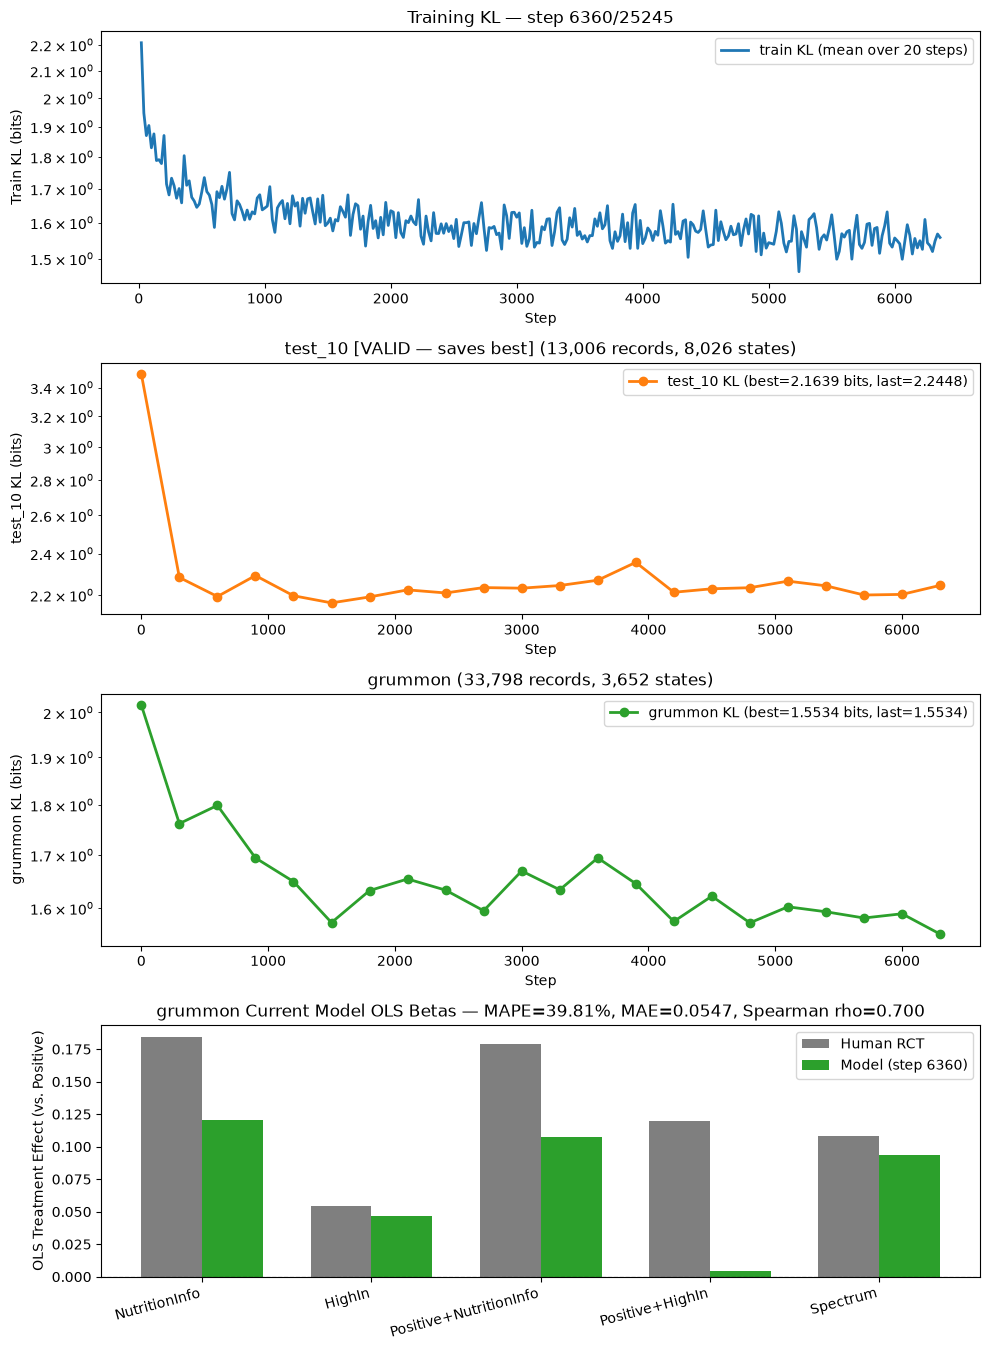

,epoch,step,train_kl,test_10_kl,grummon_kl,grummon_OLS MAPE (%),grummon_OLS MAE,grummon_OLS MSE,grummon_Spearman rho
0,0,0,—,3.4981,2.0168,104.35,0.1161,0.0148,-0.9000
1,1,300,1.6712,2.2824,1.7620,75.52,0.0996,0.0126,-0.9000
2,1,600,1.5861,2.1930,1.7989,65.41,0.0707,0.0061,-0.6000
3,1,900,1.6309,2.2916,1.6943,54.22,0.0533,0.0035,-0.1000
4,1,1200,1.5965,2.1966,1.6492,62.44,0.0862,0.0091,-0.1000
5,1,1500,1.5986,2.1639,1.5738,52.69,0.0647,0.0048,0.6000
6,1,1800,1.5340,2.1911,1.6324,43.97,0.0575,0.0042,0.7000
7,1,2100,1.5579,2.2238,1.6541,51.16,0.0669,0.0058,0.5000
8,1,2400,1.5963,2.2095,1.6332,55.41,0.0803,0.0088,0.2000
9,1,2700,1.6143,2.2345,1.5953,60.04,0.0832,0.0087,-0.3000


,human,model,abs_diff
NutritionInfo,0.1844,0.1206,0.0638
HighIn,0.0541,0.0465,0.0076
Positive+NutritionInfo,0.1788,0.1072,0.0716
Positive+HighIn,0.1194,0.0043,0.1152
Spectrum,0.1083,0.0932,0.0151


[transformers] `causal_conv1d_fn` is falling back to its reference PyTorch implementation because `causal_conv1d` is not installed. This is correct but much slower; install `causal_conv1d` for the optimized kernel.


KeyboardInterrupt: 

In [6]:
epochs = 5
lr = 5e-5
batch_size = 1                 # 1 persona group per micro-batch (zero state padding, Flash/SDPA causal path)
grad_accum_steps = 12          # 12 groups/step x ~5.54 questions/group ≈ 66.5 questions per optimizer step
# max_questions_per_group = 24
max_questions_per_group = 64
# max_chars_per_group = 6000     # bounds worst-case pass tokens to ~1,164 tokens (~6.5 GB peak VRAM)
max_chars_per_group = 20_000     
samples_per_epoch = None
warmup_steps = 2000
val_every = 300

train_set = train_records_issp_twin2k_resp

probe_groups = group_train_records(
    train_set, max_questions=max_questions_per_group, max_chars=max_chars_per_group, rng=None
)
effective_groups_bs = batch_size * grad_accum_steps
total_steps = epochs * math.ceil(len(probe_groups) / effective_groups_bs)
pct_start = min(0.1, warmup_steps / total_steps)
print(
    f"groups_per_epoch={len(probe_groups):,} (mean {len(train_set)/len(probe_groups):.2f} questions/group), "
    f"effective_groups_bs={effective_groups_bs} (~{effective_groups_bs * len(train_set) / len(probe_groups):.1f} questions/step), "
    f"total_steps={total_steps:,}, warmup_steps={int(pct_start * total_steps):,} (pct_start={pct_start:.5f})"
)
del probe_groups

plotter_s3 = train_stage(
    model,
    train_records=train_set,
    eval_records=eval_records,
    save_dir=stage3_dir,
    init_from=ckpt,
    epochs=epochs,
    lr=lr,
    pct_start=pct_start,
    batch_size=batch_size,
    grad_accum_steps=grad_accum_steps,
    max_questions_per_group=max_questions_per_group,
    max_chars_per_group=max_chars_per_group,
    val_every=val_every,
    samples_per_epoch=samples_per_epoch,
    resume=resume,
)

# Prove VRAM

In [9]:
import importlib
import data.base as _base_mod
importlib.reload(_base_mod)
from data.base import _record_chars, group_train_records


def probe_vram(model, train_records, *, max_questions, max_chars, batch_size=1, grad_accum_steps=12, epochs=5):
    """Test steady-state worst-case peak VRAM (including AdamW state buffers + gradients) without mutating model weights."""
    groups = group_train_records(train_records, max_questions=max_questions, max_chars=max_chars, rng=None)

    # Pick top candidates by padded formatted char footprint AND by max group question count
    by_padded_chars = sorted(
        groups,
        key=lambda g: len(g) * max(_record_chars(r) for r in g),
        reverse=True,
    )[:15]
    by_len = sorted(
        groups,
        key=lambda g: (len(g), max(_record_chars(r) for r in g)),
        reverse=True,
    )[:15]
    candidates = by_padded_chars + by_len

    worst_g, worst_tokens, worst_shape = None, -1, None
    for g in candidates:
        enc, _ = model.prepare(make_grouped_view(g))
        Ls = enc["seg"].count(0)
        q = max(enc["seg"])
        Lb = max(enc["seg"].count(s) for s in range(1, q + 1))
        padded_tokens = Ls + q * Lb
        if padded_tokens > worst_tokens:
            worst_tokens = padded_tokens
            worst_g = g
            worst_shape = (q, Ls, Lb)

    worst_macro = [worst_g] * batch_size
    # lr=0.0, weight_decay=0.0 allocates full fp32 AdamW state buffers without changing model weights
    opt = torch.optim.AdamW(model.trainable_parameters(), lr=0.0, weight_decay=0.0)
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda _: 1.0)
    model.train()
    if model.net.graphs is not None:
        model.net.graphs = None
    free_gpu()
    torch.cuda.reset_peak_memory_stats()

    try:
        # Step 1 allocates AdamW exp_avg/exp_avg_sq + grads; Step 2 measures true steady-state peak VRAM
        for s in range(2):
            train_one_step(model, worst_macro, batch_size, opt, sched, random.Random(0), s, 10)
        peak_alloc_gb = torch.cuda.max_memory_allocated() / (1024 ** 3)
        peak_res_gb = torch.cuda.max_memory_reserved() / (1024 ** 3)
        status = "OK"
    except torch.OutOfMemoryError:
        peak_alloc_gb = torch.cuda.max_memory_allocated() / (1024 ** 3)
        peak_res_gb = torch.cuda.max_memory_reserved() / (1024 ** 3)
        status = "OOM"
    finally:
        opt.zero_grad(set_to_none=True)
        del opt, sched
        free_gpu()

    q, Ls, Lb = worst_shape
    steps_per_epoch = math.ceil(len(groups) / (batch_size * grad_accum_steps))
    return {
        "max_questions": max_questions,
        "max_chars": max_chars,
        "groups_per_epoch": len(groups),
        "mean_q_per_group": round(len(train_records) / len(groups), 2),
        "steps_per_epoch": steps_per_epoch,
        "total_steps_5ep": epochs * steps_per_epoch,
        "worst_(Q, Ls, Lb)": f"({q}, {Ls}, {Lb})",
        "worst_padded_toks": worst_tokens,
        "peak_alloc_GiB": round(peak_alloc_gb, 2),
        "peak_reserved_GiB": round(peak_res_gb, 2),
        "status": status,
    }


if model is None:
    model = KevPointerModel.build(BASE_MODEL, device, lora_rank=LORA_RANK)
    model.net.head.temperature = 1.0

total_vram_gb = torch.cuda.get_device_properties(0).total_memory / (1024 ** 3)
print(f"GPU: {torch.cuda.get_device_name(0)} ({total_vram_gb:.1f} GiB total)")

probe_grid = [
    (24, 9600),
    (32, 12000),
    (40, 14000),
    (48, 16000),
    (56, 18000),
    (64, 20000),
    (64, 24000),
]

probe_rows = []
for mq, mc in probe_grid:
    row = probe_vram(model, train_records_issp_twin2k_resp, max_questions=mq, max_chars=mc)
    probe_rows.append(row)
    print(
        f"mq={mq:2d}, mc={mc:5d} -> {row['status']:3s} | "
        f"peak_alloc={row['peak_alloc_GiB']:5.2f} GiB (reserved={row['peak_reserved_GiB']:5.2f} GiB) | "
        f"worst={row['worst_(Q, Ls, Lb)']} ({row['worst_padded_toks']:,} toks) | "
        f"5ep_steps={row['total_steps_5ep']:,}"
    )
    if row["status"] == "OOM":
        break

df_probe = pd.DataFrame(probe_rows)
display(df_probe)

GPU: NVIDIA GeForce RTX 5090 (31.4 GiB total)
mq=24, mc= 9600 -> OK  | peak_alloc=12.52 GiB (reserved=12.79 GiB) | worst=(16, 103, 107) (1,815 toks) | 5ep_steps=46,530
mq=32, mc=12000 -> OK  | peak_alloc=15.93 GiB (reserved=16.51 GiB) | worst=(32, 111, 73) (2,447 toks) | 5ep_steps=36,710
mq=40, mc=14000 -> OK  | peak_alloc=16.92 GiB (reserved=17.43 GiB) | worst=(40, 114, 62) (2,594 toks) | 5ep_steps=32,995
mq=48, mc=16000 -> OK  | peak_alloc=20.97 GiB (reserved=21.39 GiB) | worst=(16, 94, 221) (3,630 toks) | 5ep_steps=28,910
mq=56, mc=18000 -> OK  | peak_alloc=21.93 GiB (reserved=22.61 GiB) | worst=(48, 106, 73) (3,610 toks) | 5ep_steps=27,095
mq=64, mc=20000 -> OK  | peak_alloc=25.28 GiB (reserved=25.73 GiB) | worst=(20, 94, 221) (4,514 toks) | 5ep_steps=25,245
mq=64, mc=24000 -> OK  | peak_alloc=28.04 GiB (reserved=28.79 GiB) | worst=(64, 114, 73) (4,786 toks) | 5ep_steps=22,890


,max_questions,max_chars,groups_per_epoch,mean_q_per_group,steps_per_epoch,total_steps_5ep,"worst_(Q, Ls, Lb)",worst_padded_toks,peak_alloc_GiB,peak_reserved_GiB,status
0,24,9600,111663,15.56,9306,46530,"(16, 103, 107)",1815,12.52,12.79,OK
1,32,12000,88095,19.73,7342,36710,"(32, 111, 73)",2447,15.93,16.51,OK
2,40,14000,79178,21.95,6599,32995,"(40, 114, 62)",2594,16.92,17.43,OK
3,48,16000,69374,25.05,5782,28910,"(16, 94, 221)",3630,20.97,21.39,OK
4,56,18000,65027,26.73,5419,27095,"(48, 106, 73)",3610,21.93,22.61,OK
5,64,20000,60586,28.69,5049,25245,"(20, 94, 221)",4514,25.28,25.73,OK
6,64,24000,54927,31.64,4578,22890,"(64, 114, 73)",4786,28.04,28.79,OK
